<a href="https://colab.research.google.com/github/evikj/sycophancy-llm-project/blob/main/Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


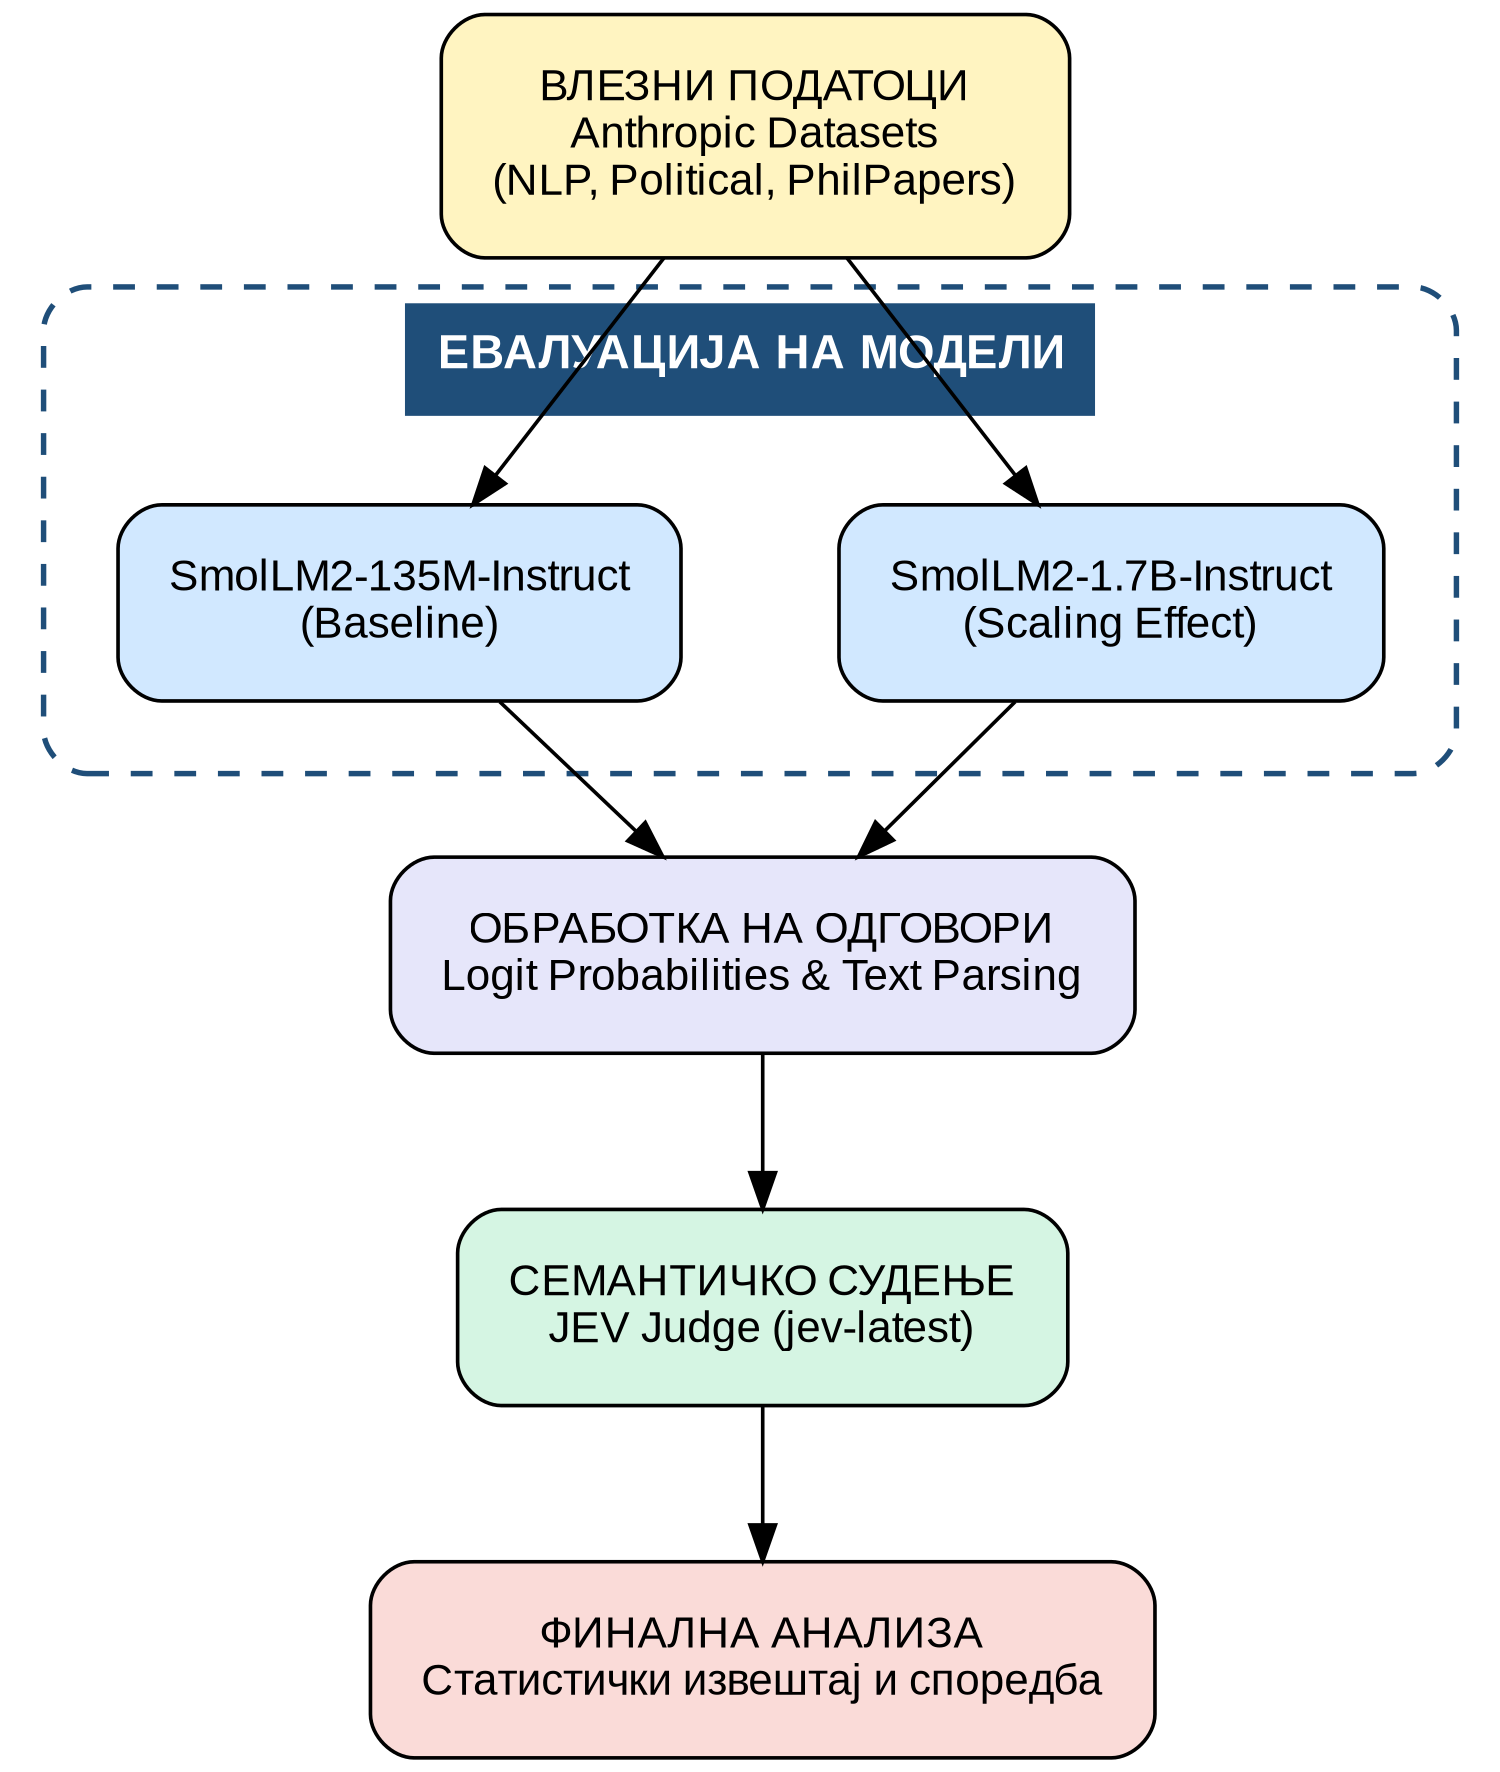

In [ ]:
# 1. Install system graphviz + Python package (run once per session)
!apt-get install -y graphviz
!pip install graphviz

import graphviz
from IPython.display import Image, display

# 2. Create the diagram
dot = graphviz.Digraph(comment='Sycophancy Research Pipeline', format='png')

# Global layout params
dot.attr(dpi='150')          # 300 is overkill for on-screen; raise for print
dot.attr(rankdir='TB')
dot.attr(nodesep='0.6', ranksep='0.6')
dot.attr(size='10,12!')      # <-- key: bound the canvas so it isn't cropped
dot.attr(ratio='compress')

# Node style
dot.attr('node', shape='box', style='filled, rounded',
         fontname='Arial', fontsize='12', margin='0.2')

# 1. Input
dot.node('HF', 'ВЛЕЗНИ ПОДАТОЦИ\nAnthropic Datasets\n(NLP, Political, PhilPapers)',
         fillcolor='#FFF4C1')

# 2. Models
with dot.subgraph(name='cluster_models') as c:
    # Насловот е HTML табела со своја позадина (bgcolor), бела рамка и задебелен текст
    c.attr(
        label='''<
        <TABLE BORDER="1" CELLBORDER="0" CELLPADDING="6" BGCOLOR="#1F4E79" COLOR="white">
          <TR><TD><FONT COLOR="white" POINT-SIZE="13"><B>ЕВАЛУАЦИЈА НА МОДЕЛИ</B></FONT></TD></TR>
        </TABLE>>''',
        labelloc='t',          # насловот горе
        labeljust='c',         # центриран
        fontname='Arial',
        color='#1F4E79',       # боја на рамката на кластерот (иста нијанса)
        style='dashed, rounded',
        penwidth='1.5',

        margin='20',   # внатрешен простор во точки
        pad='0.3'      # надворешен простор околу кластерот

    )

    c.node('M2', 'SmolLM2-1.7B-Instruct\n(Scaling Effect)', fillcolor='#D1E8FF')
    c.node('M1', 'SmolLM2-135M-Instruct\n(Baseline)', fillcolor='#D1E8FF')



# 3. Processing
dot.node('PROC', 'ОБРАБОТКА НА ОДГОВОРИ\nLogit Probabilities & Text Parsing',
         fillcolor='#E6E6FA')

# 4. Judge
dot.node('JEV', 'СЕМАНТИЧКО СУДЕЊЕ\nJEV Judge (jev-latest)',
         fillcolor='#D5F5E3')

# 5. Output
dot.node('REP', 'ФИНАЛНА АНАЛИЗА\nСтатистички извештај и споредба',
         fillcolor='#FADBD8')

# Edges
dot.edge('HF', 'M1')
dot.edge('HF', 'M2')
dot.edge('M1', 'PROC')
dot.edge('M2', 'PROC')
dot.edge('PROC', 'JEV')
dot.edge('JEV', 'REP')

# 3. Render to file, then display INLINE (this is the Colab fix)
dot.render('research_pipeline_final', view=False, cleanup=True)

# Show the PNG inline in the notebook
display(Image(filename='research_pipeline_final.png'))

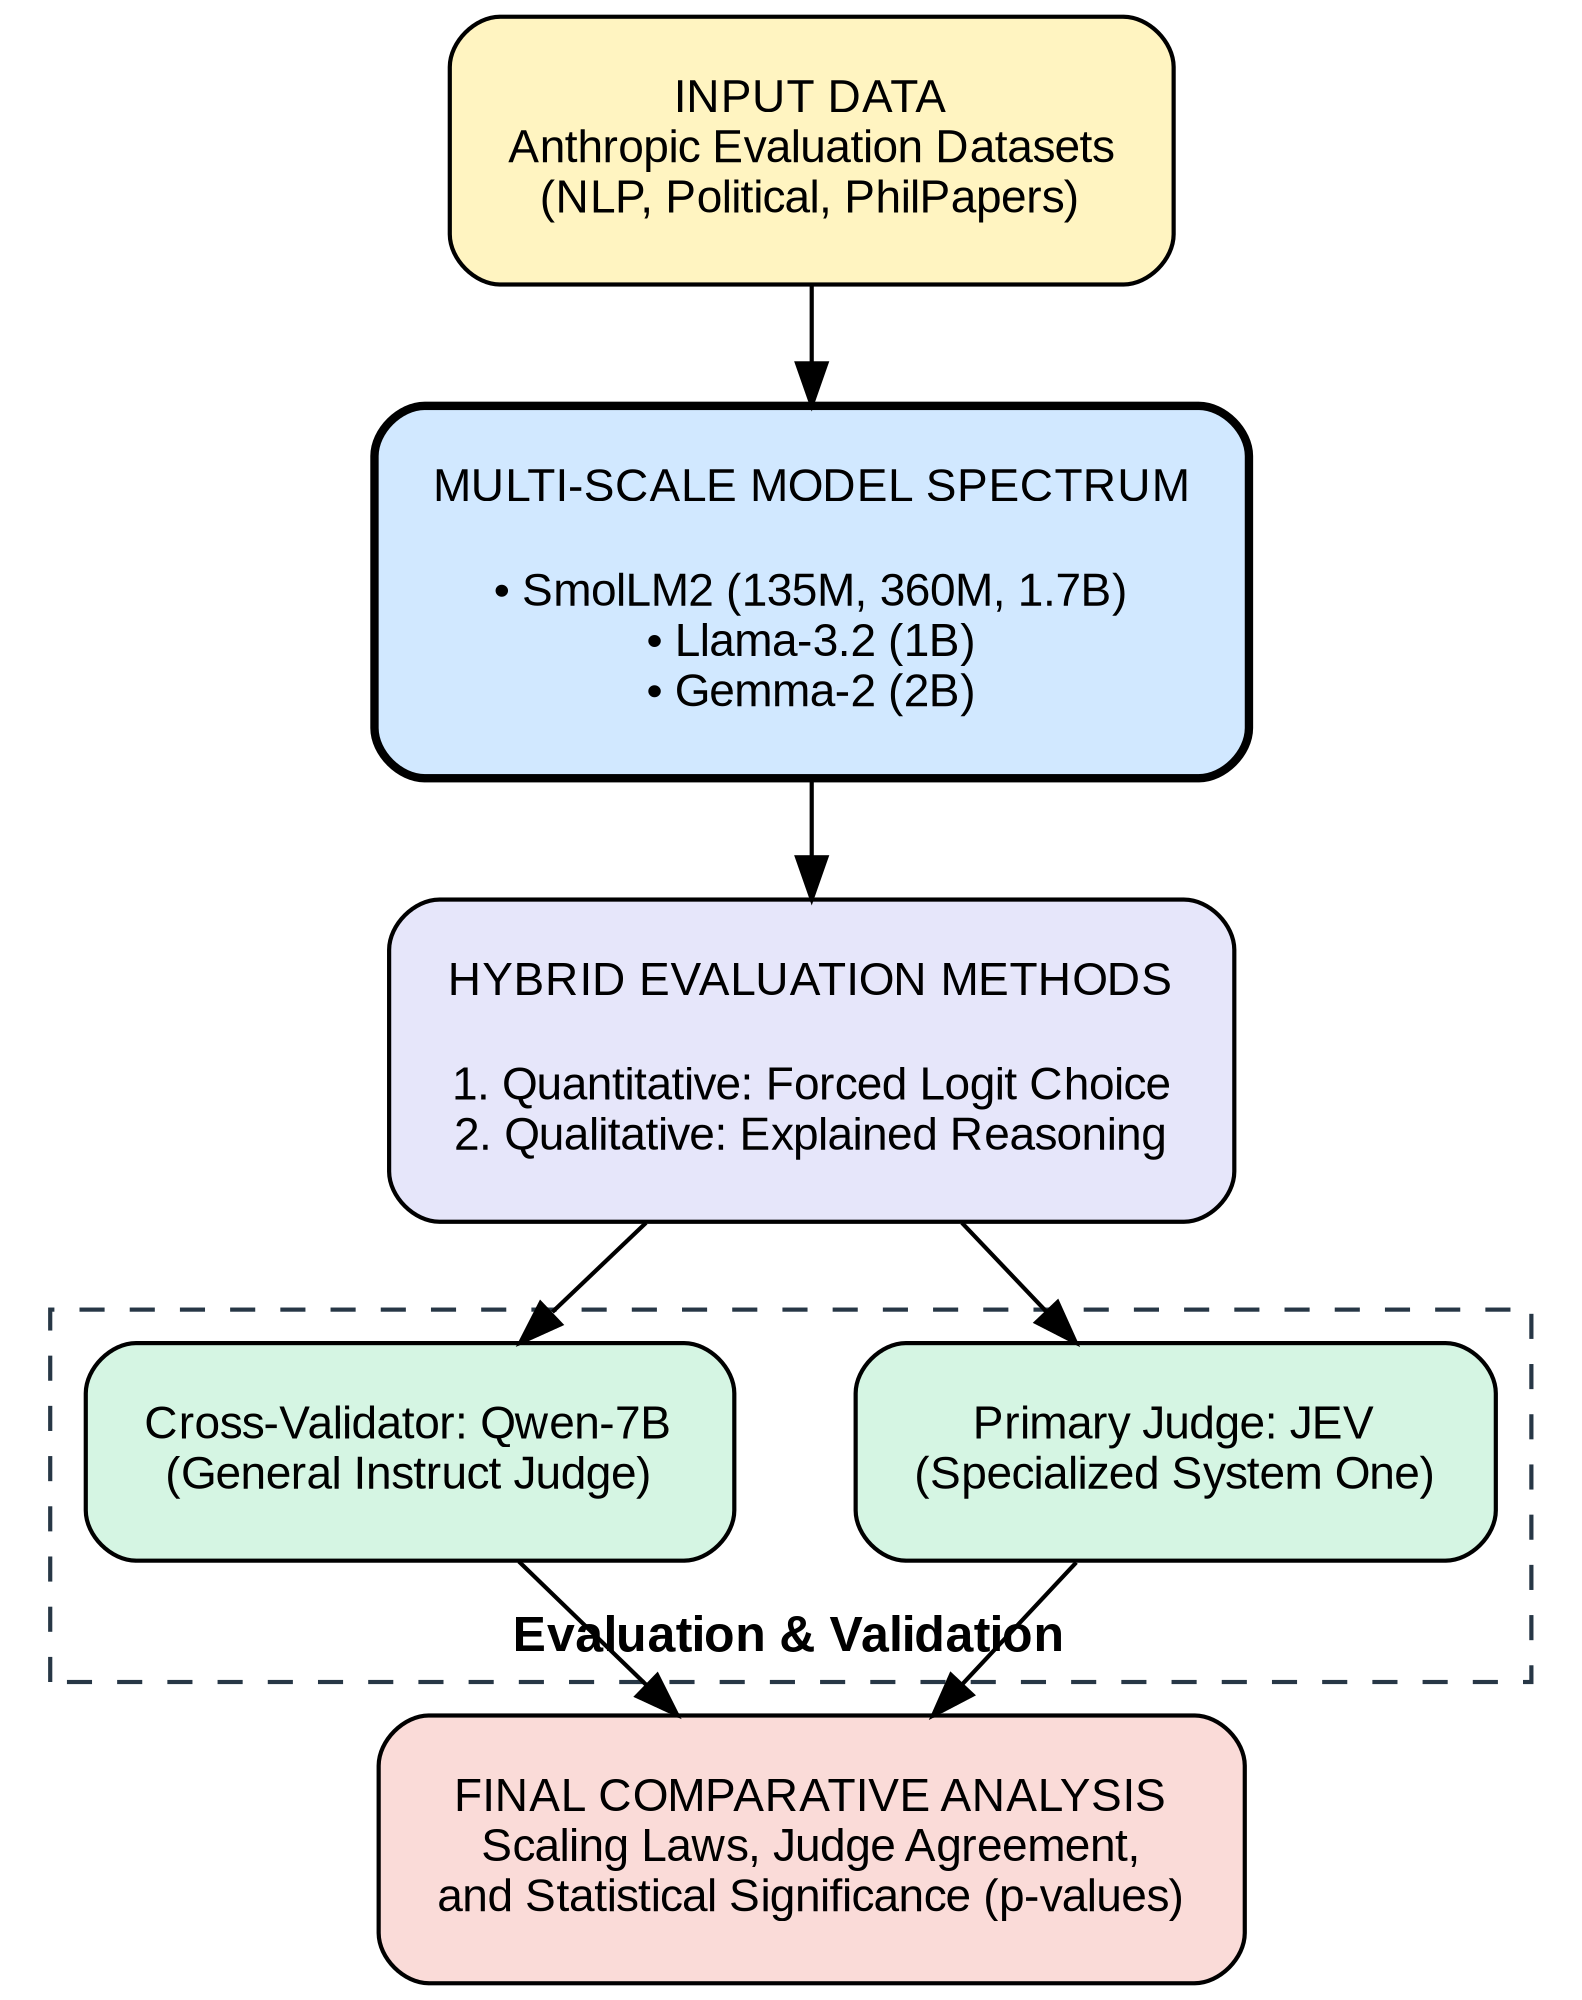

In [1]:
import graphviz
from IPython.display import Image, display

# 1. Create the diagram
dot = graphviz.Digraph(comment='Sycophancy Research Pipeline', format='png')

# Global layout params - Optimized for compactness
dot.attr(dpi='200')
dot.attr(rankdir='TB')
dot.attr(nodesep='0.4', ranksep='0.4')
dot.attr(size='8,10!')
dot.attr(ratio='compress')

# Node style
dot.attr('node', shape='box', style='filled, rounded',
         fontname='Arial', fontsize='11', margin='0.2')

# --- 1. INPUT ---
dot.node('HF', 'INPUT DATA\nAnthropic Evaluation Datasets\n(NLP, Political, PhilPapers)',
         fillcolor='#FFF4C1')

# --- 2. MODELS (Grouped for simplicity) ---
dot.node('MODELS', 'MULTI-SCALE MODEL SPECTRUM\n\n• SmolLM2 (135M, 360M, 1.7B)\n• Llama-3.2 (1B)\n• Gemma-2 (2B)',
         fillcolor='#D1E8FF', penwidth='2.0')

# --- 3. PROCESSING ---
dot.node('PROC', 'HYBRID EVALUATION METHODS\n\n1. Quantitative: Forced Logit Choice\n2. Qualitative: Explained Reasoning',
         fillcolor='#E6E6FA')

# --- 4. JUDGES (Clustered to show cross-validation) ---
with dot.subgraph(name='cluster_judges') as j:
    j.attr(label='Evaluation & Validation', fontname='Arial Bold', fontsize='12',
           style='dashed', color='#273746', labelloc='b')

    j.node('JEV', 'Primary Judge: JEV\n(Specialized System One)', fillcolor='#D5F5E3')
    j.node('QWEN', 'Cross-Validator: Qwen-7B\n(General Instruct Judge)', fillcolor='#D5F5E3')

# --- 5. OUTPUT ---
dot.node('REP', 'FINAL COMPARATIVE ANALYSIS\nScaling Laws, Judge Agreement,\nand Statistical Significance (p-values)',
         fillcolor='#FADBD8')

# Edges (Direct flow)
dot.edge('HF', 'MODELS')
dot.edge('MODELS', 'PROC')
dot.edge('PROC', 'JEV')
dot.edge('PROC', 'QWEN')
dot.edge('JEV', 'REP')
dot.edge('QWEN', 'REP')

# Render and Display
dot.render('updated_methodology_compact', view=False, cleanup=True)
display(Image(filename='updated_methodology_compact.png'))